# 🔬 Bài tập Buổi 33: Đánh giá Mô hình & Phân tích Lỗi (Error Analysis) trong Computer Vision
**Học viên:** Bùi Văn Thắng — Lớp AI Engineer K10  

**📋 Đề bài thực hành (5 Yêu cầu):**
1. **Cell 2 (Dữ liệu):** Tải `CIFAR-10`, cắt `4.000` ảnh train và `1.000` ảnh test (`float32`), ép phẳng nhãn `y_train, y_test` về 1 chiều (`.flatten()`).
2. **Cell 3 (Fine-Tuning `MobileNetV2`):** Mở khóa (unfreeze) `20` tầng tích chập cuối của `MobileNetV2` để học sâu đặc trưng ảnh.
3. **Cell 4 (Huấn luyện):** Biên dịch với `Adam(learning_rate=1e-4)` và huấn luyện `6` epochs kèm `EarlyStopping`.
4. **Cell 5 (Báo cáo từng loài):** Dùng `classification_report` in bảng điểm `Precision / Recall / F1-Score` của cả 10 loài.
5. **Cell 6 & 7 (Truy vết lỗi):** Vẽ Ma trận nhầm lẫn (`confusion_matrix` + `sns.heatmap`) và hiển thị **Top 10 ảnh mô hình tự tin đoán sai nhất**.

### 📌 Bước 1 (Cell 1): Khai báo thư viện

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix, classification_report

print("San sang phan tich loi CV voi Tensorflow:", tf.__version__)

San sang phan tich loi CV voi Tensorflow: 2.22.0-rc0


### 📌 Bước 2 (Cell 2): Tải dữ liệu `CIFAR-10` & Chuẩn bị nhãn 1 chiều (`.flatten()`)

In [4]:
(X_train_full, y_train_full), (X_test_full, y_test_full) = (cifar10.load_data())
X_train = X_train_full[:4000].astype("float32")
y_train = y_train_full[:4000].flatten()

X_test = X_test_full[:1000].astype("float32")
y_test = y_test_full[:1000].flatten()

class_names = [ "May bay", " O to", "Chim", "Meo", "Huou", "Cho", "Ech", "Ngua", "Tau Thuy", "Xe tai",]

print("Kich thuoc X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Kich thuoc X_test:", X_test.shape, "| y_test:", y_test.shape)

Kich thuoc X_train: (4000, 32, 32, 3) | y_train: (4000,)
Kich thuoc X_test: (1000, 32, 32, 3) | y_test: (1000,)


In [6]:
data_augmentation = models.Sequential(
    [layers.RandomFlip("horizontal"), layers.RandomRotation(0.1)], name="augmentation",)

base_model = MobileNetV2( input_shape=(96, 96, 3), include_top=False,weights="imagenet")
base_model.trainable = True
for layer in base_model.layers[:-20]: layer.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
x = layers.Resizing(96, 96)(x)
x = preprocess_input(x)
x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = models.Model( inputs=inputs, outputs=outputs, name="MobileNetV2_FineTuned_of_Mr_Thang_handsome")
model.summary()

Model: "MobileNetV2_FineTuned_of_Mr_Thang_handsome"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,218,890 (4.65 MB)

 Non-trainable params: 1,051,904 (4.01 MB)

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"],
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2, 
    restore_best_weights = True,
)
history = model.fit(
    X_train,
    y_train, 
    epochs=6,
    batch_size=64, 
    validation_split=0.2,
    callbacks=[early_stop],
)

Epoch 1/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.5209 - loss: 1.4215 - val_accuracy: 0.7287 - val_loss: 0.8233
Epoch 2/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.7188 - loss: 0.8333 - val_accuracy: 0.7837 - val_loss: 0.6365
Epoch 3/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.7447 - loss: 0.7466 - val_accuracy: 0.8075 - val_loss: 0.5595
Epoch 4/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.7756 - loss: 0.6440 - val_accuracy: 0.8175 - val_loss: 0.5315
Epoch 5/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.8141 - loss: 0.5305 - val_accuracy: 0.8450 - val_loss: 0.5034
Epoch 6/6
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.8275 - loss: 0.5057 - val_accuracy: 0.8288 - val_loss: 0.5060


In [14]:
test_loss, test_acc = model.evaluate( X_test, y_test, verbose=0)

print(f"Do chinh xac sau Fine Tuning tren 1.000 anh test: {test_acc*100:.2f}%\n")

y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("===Bao Cao chi tiet tung loai (classification Report)===")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Do chinh xac sau Fine Tuning tren 1.000 anh test: 82.40%

===Bao Cao chi tiet tung loai (classification Report)===
              precision    recall  f1-score   support

     May bay     0.8280    0.7476    0.7857       103
        O to     0.8776    0.9663    0.9198        89
        Chim     0.8919    0.6600    0.7586       100
         Meo     0.8023    0.6699    0.7302       103
        Huou     0.8889    0.7111    0.7901        90
         Cho     0.6961    0.8256    0.7553        86
         Ech     0.8031    0.9107    0.8536       112
        Ngua     0.7458    0.8627    0.8000       102
    Tau Thuy     0.8347    0.9528    0.8899       106
      Xe tai     0.9174    0.9174    0.9174       109

    accuracy                         0.8240      1000
   macro avg     0.8286    0.8224    0.8201      1000
weighted avg     0.8296    0.8240    0.8215      1000



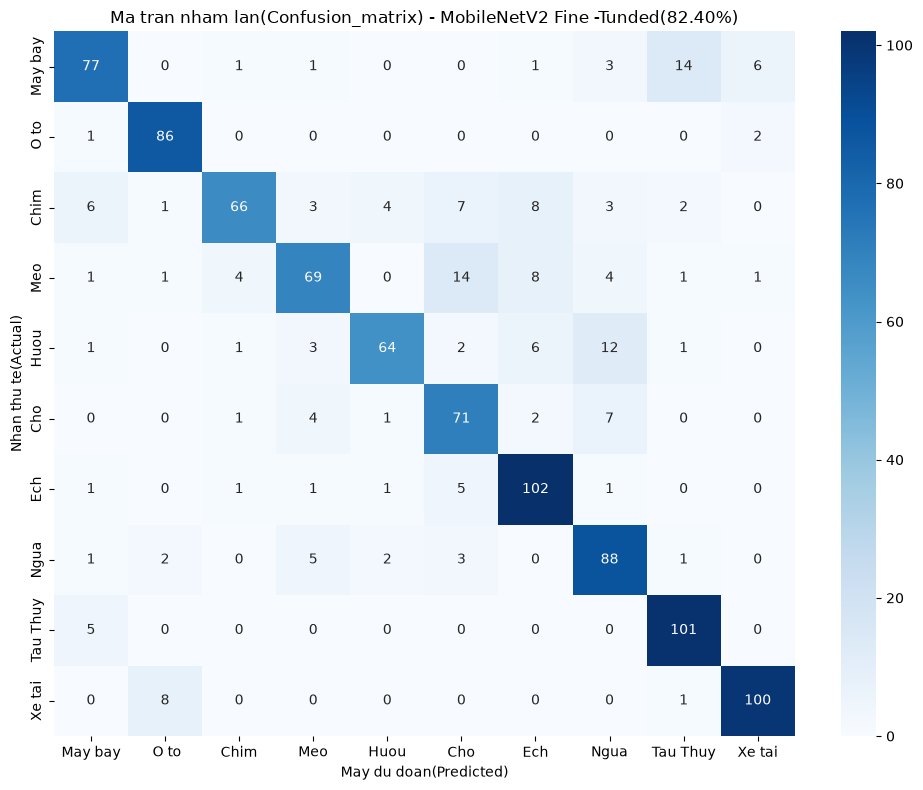

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names,
)
plt.title("Ma tran nham lan(Confusion_matrix) - MobileNetV2 Fine -Tunded(82.40%)")
plt.xlabel("May du doan(Predicted)")
plt.ylabel("Nhan thu te(Actual)")
plt.tight_layout()
plt.show()

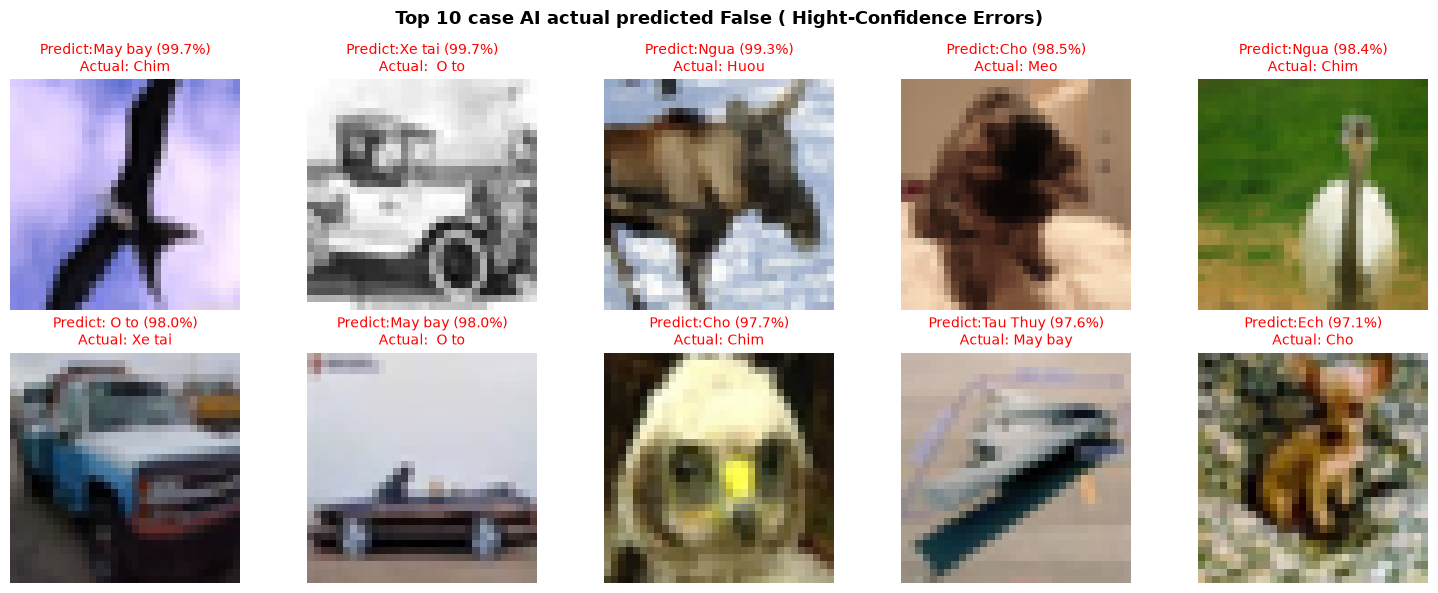

In [24]:
error_indices = np.where(y_pred != y_test)[0]
confidences = np.max(y_pred_probs, axis=1)

sorted_errors = error_indices[np.argsort(-confidences[error_indices])][:10]

plt.figure(figsize=(15, 6))
for i, idx in enumerate(sorted_errors):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].astype("uint8"))
    predict = class_names[y_pred[idx]]
    actual = class_names[y_test[idx]]
    confident = confidences[idx] * 100
    plt.title(f"Predict:{predict} ({confident:.1f}%)\nActual: {actual}", color="red", fontsize=10)
    plt.axis("off")

plt.suptitle("Top 10 case AI actual predicted False ( Hight-Confidence Errors)", fontsize=13, fontweight="bold",)

plt.tight_layout()
plt.show()